                   Model     MSE     MAE  R² Score
0      Linear Regression  0.5559  0.5332    0.5758
1  Polynomial Regression  0.4643  0.4670    0.6457


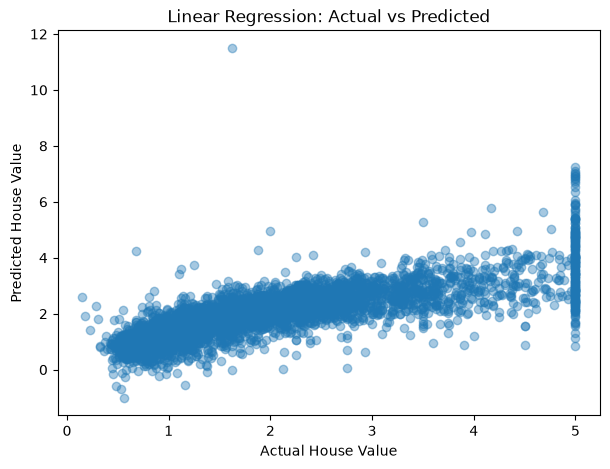

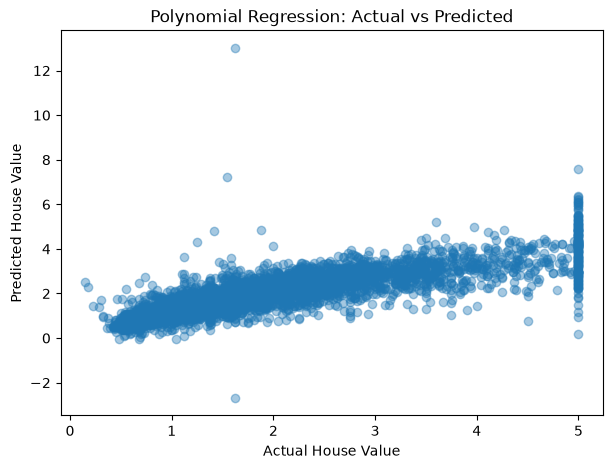

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Load your CSV file
df = pd.read_csv("California_Housing.csv")

# Change "MedHouseVal" if your target column has a different name
X = df.drop("MedHouseVal", axis=1)
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Linear Regression
linear_model = make_pipeline(StandardScaler(), LinearRegression())
linear_model.fit(X_train, y_train)
linear_pred = linear_model.predict(X_test)

# Polynomial Regression (degree 2)
poly_model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
poly_model.fit(X_train, y_train)
poly_pred = poly_model.predict(X_test)

# Compare model performance
results = pd.DataFrame({
    "Model": ["Linear Regression", "Polynomial Regression"],
    "MSE": [
        mean_squared_error(y_test, linear_pred),
        mean_squared_error(y_test, poly_pred)
    ],
    "MAE": [
        mean_absolute_error(y_test, linear_pred),
        mean_absolute_error(y_test, poly_pred)
    ],
    "R² Score": [
        r2_score(y_test, linear_pred),
        r2_score(y_test, poly_pred)
    ]
})

print(results.round(4))

# # Actual vs predicted values
# plt.scatter(y_test, linear_pred, alpha=0.4, label="Linear")
# plt.scatter(y_test, poly_pred, alpha=0.4, label="Polynomial")
# plt.xlabel("Actual House Value")
# plt.ylabel("Predicted House Value")
# plt.title("California Housing: Actual vs Predicted")
# plt.legend()
# plt.show()  ------------------------------->(Yeh bhi sahi h) or niche wala bhi sahi h dono me se koi bhi kr lo 

# Linear Regression graph
plt.figure(figsize=(7, 5))
plt.scatter(y_test, linear_pred, alpha=0.4)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Linear Regression: Actual vs Predicted")
plt.show()

# Polynomial Regression graph
plt.figure(figsize=(7, 5))
plt.scatter(y_test, poly_pred, alpha=0.4)
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title("Polynomial Regression: Actual vs Predicted")
plt.show()